# Advanced Algorithms: Approximation and Parameterized Algorithms

> **Prerequisite:** [02 · NP-completeness and reductions](02_np_completeness_and_reductions.ipynb), [`dsa/07` Graphs](../dsa/07_graphs.ipynb) (BFS/DFS, minimum spanning trees) and [`dsa/08` Greedy algorithms](../dsa/08_greedy_and_divide_and_conquer.ipynb).
>
> **Who is this for:** you know that vertex cover, set cover, TSP and knapsack are NP-hard, and you want algorithms that are fast **and** come with a written guarantee of how close to optimal they are. This is standard material in a second algorithms course (CLRS ch. 35, Vazirani's *Approximation Algorithms*) and frequent in MS/PhD exams.
>
> **What you will learn:**
> - The **approximation ratio**, and the key proof trick: **lower-bound OPT** with something you can compute
> - **Vertex cover** 2-approximation via a maximal matching, checked against the brute-force optimum, with a tight example
> - **Greedy set cover** and its H(n) ≈ ln n bound, with an instance where greedy really is about (log₂ n)/2 times worse
> - **Metric TSP**: the MST double-tree 2-approximation, Christofides (1.5), 2-opt, all compared with the exact Held–Karp optimum
> - The **knapsack FPTAS** (value scaling), with an ε vs runtime/error trade-off plot
> - **k-center** greedy 2-approximation, and its link to k-means++ seeding and core-set selection for active learning
> - **Parameterized complexity**: an FPT vertex-cover algorithm in O(2ᵏ·n), plus kernelization
> - **Inapproximability**: why general TSP cannot be approximated at all (unless P = NP)
> - **Submodular maximisation**: the greedy (1 − 1/e) guarantee, used to choose diverse documents for RAG
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb) and the notebooks above.
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

For some problems, finding the perfect answer could take longer than the age of the universe. An **approximation algorithm** gives up on perfect and instead promises "my answer is at most twice as bad as the best one", and it delivers that promise quickly, with a proof. Think of packing a car boot for a holiday: you do not try every possible arrangement, you put the big suitcases in first, and you know it will be close to the best you could do. Or a delivery driver planning a route: a good rule of thumb gets a route that is maybe 10 % longer than perfect, in seconds instead of years.

The clever part is that we can *prove* how close we are without ever knowing the perfect answer, by comparing with a number that the perfect answer can never beat. A second idea, **parameterized algorithms**, says: the problem is hard in general, but if one number (like "how many guards do I need?") is small, we can still solve it exactly and fast.

**Tiny example.** A museum has 3 corridors: A–B, B–C and C–D. A guard standing at a room watches every corridor that touches that room. The best plan uses 2 guards (at B and C). The quick rule "pick any unwatched corridor and put guards at *both* ends" might pick A–B, then C–D: 4 guards. That is never more than 2 × the best (here exactly 2 × 2 = 4), no matter how big the museum.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Approximation ratio | a proven "at most X times worse than perfect" | delivery routing, chip layout, cloud server packing |
| FPTAS | you choose the accuracy (say 99 %) and pay more time for more accuracy | budget allocation, knapsack-style ad selection |
| Submodular greedy | keep adding the item that adds the most *new* value | picking diverse documents for an LLM's context (RAG), summarisation |

### How this notebook is different from what you have seen
[`classical_ai/04`](../classical_ai/04_local_search_and_optimization.ipynb) improves tours and N-Queens boards with heuristics (hill climbing, simulated annealing): often excellent, but with no guarantee. [`dsa/08`](../dsa/08_greedy_and_divide_and_conquer.ipynb) shows greedy algorithms that are *exactly* optimal. Here we are in between: greedy and other fast algorithms that are **provably within a factor** of optimal on every input.

## Table of contents
1. Approximation ratios and lower-bounding OPT
2. Vertex cover: a 2-approximation via maximal matching
3. Greedy set cover and the H(n) bound
4. Metric TSP: double tree, Christofides and 2-opt
5. Knapsack FPTAS
6. k-center: farthest-first traversal
7. Parameterized complexity: FPT vertex cover
8. Inapproximability
9. How this connects to modern AI: submodular maximisation for RAG
10. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import itertools
from collections import Counter
import networkx as nx

def min_vertex_cover_exact(G):
    """Exact minimum vertex cover: complement of a maximum independent set,
    found as a maximum clique of the complement graph (networkx, exact)."""
    if G.number_of_edges() == 0:
        return set()
    clique, _ = nx.max_weight_clique(nx.complement(G), weight=None)
    return set(G.nodes()) - set(clique)

def is_vertex_cover(G, C):
    return all(u in C or v in C for u, v in G.edges())

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Approximation ratios and lower-bounding OPT

> 💬 **In plain English:** we cannot know the perfect answer, so we compare ours with a number the perfect answer can never beat.

Let C* be the cost of an optimal solution (OPT) and C the cost of our algorithm's solution. An algorithm is a **ρ-approximation** (has **approximation ratio** ρ ≥ 1) if, on every input of size n,

$$\max\Big(\frac{C}{C^*}, \frac{C^*}{C}\Big) \le \rho(n).$$

For a **minimisation** problem this says C ≤ ρ·C*. For a **maximisation** problem it says C ≥ C*/ρ (some books write this as C ≥ α·C* with α = 1/ρ ≤ 1, e.g. "a (1 − 1/e)-approximation").

| Kind of guarantee | Meaning | Example |
|---|---|---|
| constant factor | ρ is a fixed number | vertex cover 2, metric TSP 1.5 |
| logarithmic | ρ = O(log n) | set cover H(n) ≈ ln n |
| **PTAS** | for every fixed ε > 0, a (1 + ε)-approximation in time polynomial in n (maybe exponential in 1/ε) | Euclidean TSP (Arora 1998) |
| **FPTAS** | (1 + ε)-approximation in time polynomial in **both** n and 1/ε | knapsack (section 5) |

**The central proof trick.** We cannot compute C* (that is NP-hard), so we find a quantity **L ≤ C*** (a lower bound, for minimisation) that we *can* compute, and show C ≤ ρ·L. Then C ≤ ρ·L ≤ ρ·C*. Lower bounds used below:

| Problem | Lower bound on OPT | Why |
|---|---|---|
| vertex cover | size of any matching | each matched edge needs its own cover vertex |
| metric TSP | MST weight | removing one edge of the optimal tour leaves a spanning tree |
| k-center | half the distance between k + 1 mutually far points | two of them share a centre (pigeonhole) |

---
## 2. Vertex cover: a 2-approximation via maximal matching

> 💬 **In plain English:** put guards at both ends of uncovered corridors; you never use more than twice the minimum.

A **vertex cover** is a set C of vertices touching every edge. A **matching** is a set of edges with no shared endpoints; it is **maximal** if no edge can be added.

**Algorithm (APPROX-VERTEX-COVER, CLRS §35.1).** While some edge (u, v) is uncovered, add **both** u and v to C. The chosen edges form a maximal matching M, and |C| = 2|M|.

**Proof of the ratio 2.** The edges of M share no endpoints, so any cover (including the optimal one) needs a *different* vertex for each of them: |C*| ≥ |M|. Hence |C| = 2|M| ≤ 2|C*|. ∎

**Time:** O(V + E), one pass over the edges.

294 random graphs: mean ratio 1.615, worst ratio 2.000 (guarantee: 2)
10 disjoint edges: approx = 20, OPT = 10 → ratio exactly 2


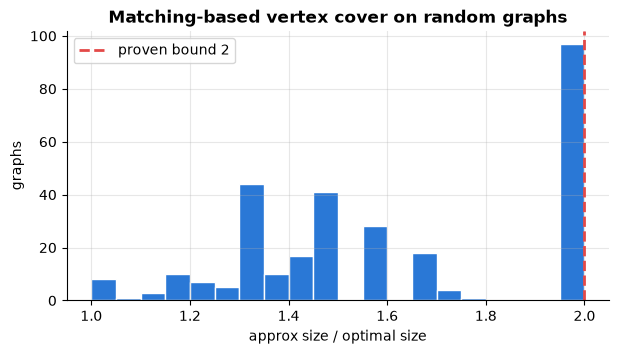

In [2]:
def approx_vertex_cover(G):
    """2-approximation: take both endpoints of every edge of a greedily built maximal matching."""
    cover, matching = set(), []
    for u, v in G.edges():
        if u not in cover and v not in cover:   # edge still uncovered → add it to the matching
            cover |= {u, v}
            matching.append((u, v))
    return cover, matching

rng = random.Random(0)
rows = []
for t in range(300):
    n = rng.randint(4, 16)
    G = nx.gnp_random_graph(n, rng.uniform(0.1, 0.6), seed=t)
    if G.number_of_edges() == 0:
        continue
    C, M = approx_vertex_cover(G)
    opt = min_vertex_cover_exact(G)
    assert is_vertex_cover(G, C) and is_vertex_cover(G, opt)
    assert len(M) <= len(opt) <= len(C) <= 2 * len(opt)           # the whole proof, checked
    rows.append({"n": n, "matching": len(M), "OPT": len(opt), "approx": len(C), "ratio": len(C) / len(opt)})
vc = pd.DataFrame(rows)
print(f"{len(vc)} random graphs: mean ratio {vc.ratio.mean():.3f}, worst ratio {vc.ratio.max():.3f} (guarantee: 2)")

# Tight example: a perfect matching of 10 disjoint edges
T = nx.Graph([(2 * i, 2 * i + 1) for i in range(10)])
C, _ = approx_vertex_cover(T)
print(f"10 disjoint edges: approx = {len(C)}, OPT = {len(min_vertex_cover_exact(T))} → ratio exactly 2")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(vc.ratio, bins=np.arange(1, 2.05, 0.05), color=PALETTE[0], edgecolor="white")
ax.axvline(2, color=PALETTE[7], ls="--", label="proven bound 2")
ax.set(xlabel="approx size / optimal size", ylabel="graphs", title="Matching-based vertex cover on random graphs"); ax.legend()
plt.show()

**What just happened?** On every random graph the chain |M| ≤ |C*| ≤ |C| ≤ 2|C*| held: that assert *is* the proof, checked numerically. Typical ratios are well below 2 (the mean is printed above), but the 10-disjoint-edges graph shows the bound is **tight**: the algorithm takes 20 vertices where 10 suffice.

> ⚠️ **Common mistake:** "greedily take the vertex of highest degree" sounds smarter, but its worst-case ratio grows like ln n (it is the set-cover greedy of the next section in disguise). Smart-looking ≠ provably good.

> 🎓 **Exam / interview tip:** better than 2 is not known. Vertex cover cannot be approximated within √2 − ε unless P = NP (Khot, Minzer & Safra, 2018), and not within 2 − ε if the Unique Games Conjecture holds (Khot & Regev, 2008).

---
## 3. Greedy set cover and the H(n) bound

> 💬 **In plain English:** keep choosing the set that covers the most new things; you are at most about ln n times worse than the best.

**Set cover:** given a universe U of n elements and a family of subsets S₁, …, S_m whose union is U, choose the fewest subsets that still cover U. Example: choose the fewest radio towers so that every town gets a signal.

**Greedy:** repeatedly pick the set that covers the **most still-uncovered** elements.

**Guarantee (Johnson 1974, Lovász 1975, Chvátal 1979).** Greedy uses at most **H(d) · OPT** sets, where d is the size of the largest set and H(d) = 1 + ½ + … + 1/d ≤ ln d + 1. Since d ≤ n, the ratio is at most H(n) ≈ ln n.

*Proof sketch (charging).* When greedy picks a set that newly covers k elements, charge each of them 1/k. The total charge equals the number of sets greedy picks. Look at any set S of the optimal cover: when it still has r uncovered elements, greedy's choice covers at least r new ones, so the next element of S to be covered is charged at most 1/r. Over S that is at most 1/|S| + … + 1/2 + 1 = H(|S|) ≤ H(d). Summing over the OPT sets gives ≤ H(d)·OPT. ∎

**Time:** O(Σ|S_i| · m) naively; O(Σ|S_i|) with bucket queues.

In [3]:
def greedy_set_cover(universe, sets):
    """Return the indices of the chosen sets."""
    uncovered, chosen = set(universe), []
    while uncovered:
        i = max(range(len(sets)), key=lambda j: len(sets[j] & uncovered))   # most new elements
        if not sets[i] & uncovered:
            raise ValueError("the sets do not cover the universe")
        chosen.append(i)
        uncovered -= sets[i]
    return chosen

def optimal_set_cover(universe, sets):
    """Brute force: try k = 1, 2, ... sets."""
    U = set(universe)
    for k in range(1, len(sets) + 1):
        for combo in itertools.combinations(range(len(sets)), k):
            if set().union(*(sets[i] for i in combo)) >= U:
                return list(combo)

def H(d): return sum(1 / i for i in range(1, d + 1))

rng = random.Random(1)
ratios = []
for t in range(150):
    U = list(range(20))
    sets = [set(rng.sample(U, rng.randint(2, 7))) for _ in range(14)]
    sets.append(set(rng.sample(U, 10)))                         # make sure every element is coverable
    missing = set(U) - set().union(*sets)
    sets[0] |= missing
    g, o = greedy_set_cover(U, sets), optimal_set_cover(U, sets)
    d = max(len(s) for s in sets)
    assert len(g) <= H(d) * len(o) + 1e-9
    ratios.append(len(g) / len(o))
print(f"150 random instances: greedy/OPT mean {np.mean(ratios):.3f}, worst {max(ratios):.3f}; "
      f"greedy optimal in {np.mean(np.array(ratios) == 1):.0%} of them")

150 random instances: greedy/OPT mean 1.048, worst 1.400; greedy optimal in 78% of them


The random instances are kind to greedy. Here is a family that is not. Two rows A and B each have 2ᵏ − 1 elements, cut into blocks of sizes 1, 2, 4, …, 2ᵏ⁻¹. The sets are: row A, row B, and for each i the "column" C_i = block i of A ∪ block i of B. OPT = 2 (the two rows). But C_{k−1} has 2ᵏ elements, one more than a row, so greedy grabs it. After that, the next column is again slightly bigger than what is left of each row, and so on: greedy picks all **k** columns.

```
k = 3:   row A: [a1][a2 a3][a4 a5 a6 a7]      greedy picks C2 (8 elements) > row (7)
         row B: [b1][b2 b3][b4 b5 b6 b7]      then C1 (4) > what is left of a row (3), then C0
                 C0   C1       C2
```

In [4]:
def bad_set_cover_instance(k):
    rowA, rowB, cols, start = set(), set(), [], 0
    for i in range(k):
        block = range(start, start + 2**i); start += 2**i
        A = {("a", x) for x in block}; B = {("b", x) for x in block}
        rowA |= A; rowB |= B; cols.append(A | B)
    return rowA | rowB, [rowA, rowB] + cols

rows = []
for k in range(2, 13):
    U, sets = bad_set_cover_instance(k)
    g = greedy_set_cover(U, sets)
    assert set(sets[0]) | set(sets[1]) == U                       # OPT = 2: the two rows
    rows.append({"k": k, "n = |U|": len(U), "greedy sets": len(g), "OPT": 2, "ratio": len(g) / 2,
                 "H(max set size)": round(H(max(len(s) for s in sets)), 2)})
bad = pd.DataFrame(rows)
print(bad.to_string(index=False))

 k  n = |U|  greedy sets  OPT  ratio  H(max set size)
 2        6            2    2    1.0             2.08
 3       14            3    2    1.5             2.72
 4       30            4    2    2.0             3.38
 5       62            5    2    2.5             4.06
 6      126            6    2    3.0             4.74
 7      254            7    2    3.5             5.43
 8      510            8    2    4.0             6.12
 9     1022            9    2    4.5             6.82
10     2046           10    2    5.0             7.51
11     4094           11    2    5.5             8.20
12     8190           12    2    6.0             8.90


**What just happened?** On random instances greedy was usually optimal or close. On the constructed family it picks k sets while OPT is 2, so the ratio k/2 ≈ ½·log₂ n keeps growing with n, always staying below the proven H(d) bound in the last column. So the logarithmic factor is real. It is also the best possible: set cover cannot be approximated within (1 − ε)·ln n unless P = NP (Dinur & Steurer, 2014).

---
## 4. Metric TSP: double tree, Christofides and 2-opt

> 💬 **In plain English:** build a cheap tree through all cities, walk around it and skip repeats; the trip is at most twice the shortest.

**Metric TSP:** visit all n cities and return, minimising total distance, where distances obey the **triangle inequality** d(a, c) ≤ d(a, b) + d(b, c) (true for road or straight-line distances).

**Double-tree algorithm (2-approximation).**
1. Build a minimum spanning tree T (Prim's algorithm).
2. Walk around the tree (DFS), which uses every tree edge twice: cost 2·w(T).
3. **Shortcut**: visit vertices in DFS preorder, skipping repeats. By the triangle inequality, shortcuts never increase the length.

Since deleting one edge from the optimal tour gives a spanning tree, w(T) ≤ OPT, so the tour ≤ 2·w(T) ≤ **2·OPT**.

**Christofides (1976; also Serdyukov 1978): ratio 1.5.** Instead of doubling the whole tree, add a **minimum-weight perfect matching** on the odd-degree vertices of T (weight ≤ OPT/2), take an Euler circuit and shortcut it. For 45 years 1.5 was the best known; Karlin, Klein & Oveis Gharan (2021) improved it to 1.5 − 10⁻³⁶, a tiny but theoretically important step.

**2-opt** is a local-search *heuristic* (no worst-case guarantee better than O(log n)-ish in theory, but excellent in practice): repeatedly reverse a segment of the tour when that shortens it (it removes crossings).

**Exact baseline: Held–Karp** dynamic programming over subsets, O(n²·2ⁿ) time (as in [`dsa/09`](../dsa/09_dynamic_programming.ipynb)), feasible for n ≤ ~15 in Python.

In [5]:
def dist_matrix(pts):
    return np.sqrt(((pts[:, None, :] - pts[None, :, :]) ** 2).sum(-1))

def tour_length(D, tour):
    return sum(D[tour[i], tour[(i + 1) % len(tour)]] for i in range(len(tour)))

def prim_mst(D):
    """Prim's algorithm on a complete graph in O(n^2). Returns the parent array."""
    n = len(D)
    in_tree = [False] * n; best = [math.inf] * n; parent = [-1] * n
    best[0] = 0
    for _ in range(n):
        u = min((i for i in range(n) if not in_tree[i]), key=lambda i: best[i])
        in_tree[u] = True
        for v in range(n):
            if not in_tree[v] and D[u, v] < best[v]:
                best[v], parent[v] = D[u, v], u
    return parent

def double_tree_tour(D):
    parent = prim_mst(D)
    children = {i: [] for i in range(len(D))}
    for v, p in enumerate(parent):
        if p >= 0: children[p].append(v)
    tour, stack = [], [0]
    while stack:                                   # preorder DFS = walk around the tree with shortcuts
        u = stack.pop(); tour.append(u)
        stack.extend(reversed(children[u]))
    mst_weight = sum(D[v, p] for v, p in enumerate(parent) if p >= 0)
    return tour, mst_weight

def two_opt(D, tour):
    """Reverse tour[i..j] whenever that shortens the tour, until no improvement."""
    tour = list(tour); n = len(tour); improved = True
    while improved:
        improved = False
        for i in range(1, n - 1):
            for j in range(i + 1, n):
                a, b, c, d = tour[i - 1], tour[i], tour[j], tour[(j + 1) % n]
                if D[a, c] + D[b, d] < D[a, b] + D[c, d] - 1e-12:   # swap edges (a,b),(c,d) → (a,c),(b,d)
                    tour[i:j + 1] = reversed(tour[i:j + 1]); improved = True
    return tour

def held_karp(D):
    """Exact TSP by DP over subsets: O(n^2 2^n). best[(mask, j)] = shortest path from 0 visiting mask, ending at j."""
    n = len(D)
    best = {(1 | 1 << j, j): D[0, j] for j in range(1, n)}
    for size in range(3, n + 1):
        for subset in itertools.combinations(range(1, n), size - 1):
            mask = 1 | sum(1 << j for j in subset)
            for j in subset:
                prev = mask ^ (1 << j)
                best[(mask, j)] = min(best[(prev, k)] + D[k, j] for k in subset if k != j)
    full = (1 << n) - 1
    return min(best[(full, j)] + D[j, 0] for j in range(1, n))

def christofides_tour(D):
    G = nx.complete_graph(len(D))
    for u, v in G.edges(): G[u][v]["weight"] = D[u, v]
    cycle = nx.approximation.christofides(G, weight="weight")
    return cycle[:-1]                                  # networkx repeats the start node at the end

rng_np = np.random.default_rng(3)
rows = []
for t in range(20):
    pts = rng_np.random((10, 2))
    D = dist_matrix(pts)
    opt = held_karp(D)
    dt_tour, mst_w = double_tree_tour(D)
    ch = christofides_tour(D)
    for name, tour in [("double tree", dt_tour), ("Christofides", ch), ("double tree + 2-opt", two_opt(D, dt_tour))]:
        assert sorted(tour) == list(range(10))
        rows.append({"method": name, "ratio": tour_length(D, tour) / opt})
    assert mst_w <= opt + 1e-9 and tour_length(D, dt_tour) <= 2 * opt + 1e-9
tsp = pd.DataFrame(rows)
print("Tour length / optimal (Held-Karp), 20 random instances with n = 10:")
print(tsp.groupby("method").ratio.agg(["mean", "max"]).round(3))

Tour length / optimal (Held-Karp), 20 random instances with n = 10:
                      mean    max
method                           
Christofides         1.052  1.195
double tree          1.205  1.453
double tree + 2-opt  1.019  1.145


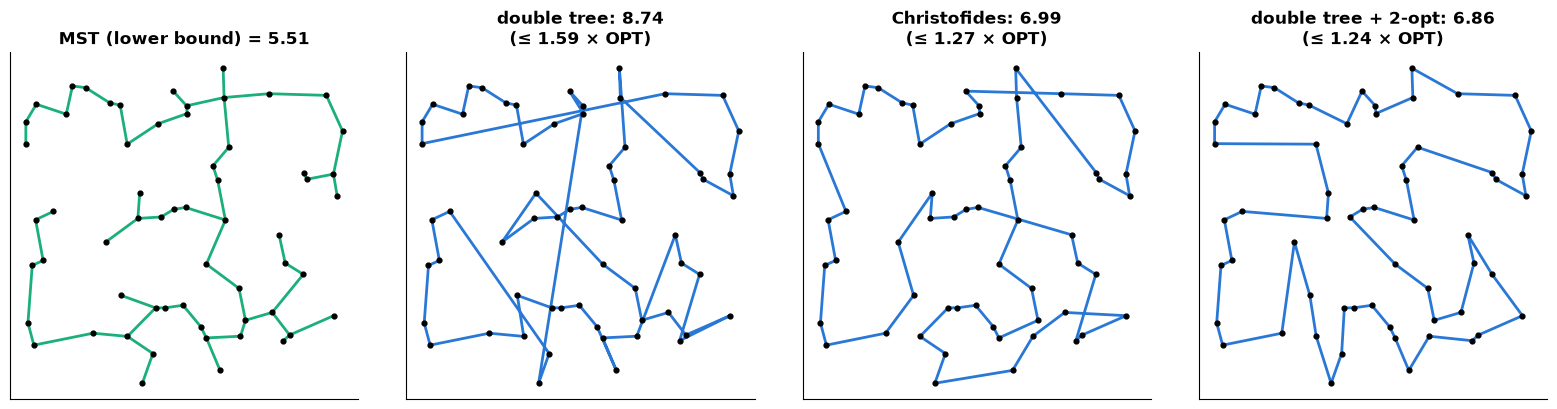

In [6]:
# One bigger instance (n = 60): exact is out of reach, so compare with the MST lower bound
pts = np.random.default_rng(7).random((60, 2))
D = dist_matrix(pts)
dt_tour, mst_w = double_tree_tour(D)
tours = {"double tree": dt_tour, "Christofides": christofides_tour(D), "double tree + 2-opt": two_opt(D, dt_tour)}
parent = prim_mst(D)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for v, p in enumerate(parent):
    if p >= 0: axes[0].plot(*pts[[v, p]].T, color=PALETTE[2])
axes[0].set_title(f"MST (lower bound) = {mst_w:.2f}")
for ax, (name, tour) in zip(axes[1:], tours.items()):
    cyc = tour + [tour[0]]
    ax.plot(pts[cyc, 0], pts[cyc, 1], "-", color=PALETTE[0])
    ax.set_title(f"{name}: {tour_length(D, tour):.2f}\n(≤ {tour_length(D, tour) / mst_w:.2f} × OPT)")
for ax in axes:
    ax.scatter(*pts.T, s=12, color="black", zorder=3); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

**What just happened?**
- On 20 exact-solvable instances, all methods respected their guarantees. In the printed table the double tree is typically 20–30 % above optimal (its proof only promises ≤ 100 %), Christofides is usually better, and 2-opt polishing gets within a few percent.
- For n = 60 we cannot compute OPT, but the MST weight is a lower bound, so length / MST is an **upper bound on the true ratio** that we can certify without knowing OPT. That is the lower-bounding trick in action.
- In the plots, the double-tree tour has visible crossings; 2-opt removes them (a tour with a crossing can always be shortened in the Euclidean plane).

| Method | Guarantee | Time | Notes |
|---|---|---|---|
| Held–Karp DP | exact | O(n²2ⁿ) | n ≤ ~15 in Python, ~30 in C |
| double tree | 2 | O(n²) (Prim on a dense graph) | simplest proof |
| Christofides | 1.5 | O(n³) (matching) | the classic exam answer |
| 2-opt | heuristic | O(n²) per pass | great in practice; combine with any start tour |
| Lin–Kernighan / LKH, Concorde | heuristic / exact | – | the real-world tools |

---
## 5. Knapsack FPTAS

> 💬 **In plain English:** round the item values to coarse numbers, solve exactly, and lose at most a chosen percentage ε.

The 0/1 knapsack DP over capacities costs O(nW), which is pseudo-polynomial ([02 §8](02_np_completeness_and_reductions.ipynb)). There is a *second* DP, over **values**: let A[v] = the minimum weight needed to reach total value exactly v. That costs O(n·V), where V = Σ values. It is also pseudo-polynomial, but now we can make the values small by **rounding** them.

**FPTAS (Ibarra & Kim 1975).** Given ε > 0:
1. Let v_max be the largest value and K = ε·v_max / n.
2. Round down: v'_i = ⌊v_i / K⌋. Now every v'_i ≤ n/ε.
3. Solve the value-DP exactly on the rounded values: O(n · Σv') = O(n³/ε) time.
4. Return that item set (evaluated with the true values).

**Why it is (1 − ε)-optimal.** Rounding loses less than K per item, so at most nK = ε·v_max in total, and v_max ≤ OPT (assuming every single item fits). So value ≥ OPT − ε·v_max ≥ (1 − ε)·OPT.

Time is polynomial in n **and** 1/ε: a fully polynomial-time approximation scheme. Strongly NP-hard problems (like bin packing or TSP) have no FPTAS unless P = NP.

In [7]:
def knapsack_exact(weights, values, W):
    """Exact 0/1 knapsack, DP over capacities (NumPy rows), O(nW). Returns the best value."""
    dp = np.zeros(W + 1, dtype=np.int64)
    for w, v in zip(weights, values):
        if w <= W:
            dp[w:] = np.maximum(dp[w:], dp[:W + 1 - w] + v)
    return int(dp[W])

def knapsack_by_value(weights, values, W):
    """Exact DP over values: A[v] = min weight to get value v. Returns the chosen item indices."""
    V = sum(values)
    INF = np.iinfo(np.int64).max // 4
    A = np.full(V + 1, INF, dtype=np.int64); A[0] = 0
    take = np.zeros((len(values), V + 1), dtype=bool)          # for reconstructing the item set
    for i, (w, v) in enumerate(zip(weights, values)):
        if v == 0:
            continue
        cand = np.full(V + 1, INF, dtype=np.int64)
        cand[v:] = A[:V + 1 - v] + w                             # take item i
        better = cand < A
        take[i] = better
        A = np.where(better, cand, A)
    best_v = int(np.max(np.nonzero(A <= W)[0]))
    items, v = [], best_v                                        # walk back through the decisions
    for i in range(len(values) - 1, -1, -1):
        if take[i, v]:
            items.append(i); v -= values[i]
    return items

def knapsack_fptas(weights, values, W, eps):
    n = len(values)
    K = eps * max(values) / n
    scaled = [int(v // K) for v in values]                       # rounded-down values, each <= n/eps
    return knapsack_by_value(weights, scaled, W)

# Correctness of the value-DP against the capacity-DP on small instances
rng = random.Random(4)
for _ in range(200):
    n = rng.randint(1, 12)
    w = [rng.randint(1, 30) for _ in range(n)]; v = [rng.randint(0, 40) for _ in range(n)]; W = rng.randint(1, 80)
    items = knapsack_by_value(w, v, W)
    assert sum(w[i] for i in items) <= W and sum(v[i] for i in items) == knapsack_exact(w, v, W)
print("value-DP matches capacity-DP on 200 random instances")

# A "strongly correlated" instance (value ≈ 100 × weight): the classic hard family, full of near-ties
rng = random.Random(0)
n = 60
weights = [rng.randint(1000, 10_000) for _ in range(n)]
values = [w * 100 + rng.randint(0, 20_000) for w in weights]
W = sum(weights) // 3
t0 = time.perf_counter(); OPT = knapsack_exact(weights, values, W); t_exact = time.perf_counter() - t0
rows = []
for eps in [0.5, 0.3, 0.2, 0.1, 0.05, 0.02]:
    t0 = time.perf_counter(); items = knapsack_fptas(weights, values, W, eps); dt = time.perf_counter() - t0
    val = sum(values[i] for i in items)
    assert sum(weights[i] for i in items) <= W and val >= (1 - eps) * OPT
    rows.append({"eps": eps, "value / OPT": val / OPT, "guarantee 1-eps": 1 - eps, "seconds": dt,
                 "DP size (Σ scaled values)": sum(int(v // (eps * max(values) / n)) for v in values)})
fp = pd.DataFrame(rows)
print(f"exact DP over capacities (W = {W:,}): {t_exact:.3f} s, OPT = {OPT:,}")
print(fp.to_string(index=False, formatters={"value / OPT": "{:.5f}".format, "seconds": "{:.3f}".format}))

value-DP matches capacity-DP on 200 random instances
exact DP over capacities (W = 115,971): 0.024 s, OPT = 11,961,638
 eps value / OPT  guarantee 1-eps seconds  DP size (Σ scaled values)
0.50     0.99752             0.50   0.003                       4141
0.30     0.99899             0.70   0.004                       6917
0.20     0.99931             0.80   0.006                      10397
0.10     1.00000             0.90   0.010                      20827
0.05     1.00000             0.95   0.020                      41680
0.02     0.99998             0.98   0.123                     104250


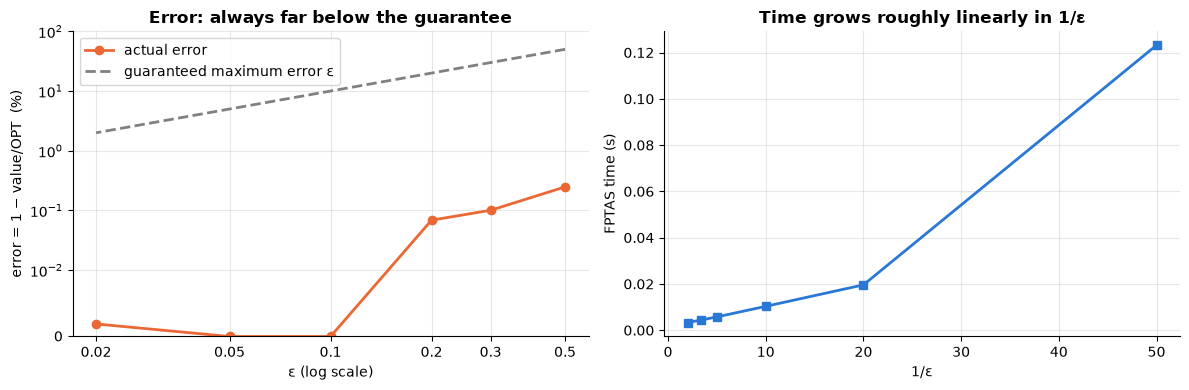

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(fp.eps, 100 * (1 - fp["value / OPT"]), "o-", color=PALETTE[1], label="actual error")
ax.plot(fp.eps, 100 * fp.eps, "--", color="gray", label="guaranteed maximum error ε")
ax.set_xscale("log"); ax.set_xticks(fp.eps, [str(e) for e in fp.eps]); ax.minorticks_off()
ax.set_yscale("symlog", linthresh=1e-2); ax.set_ylim(0, 100)
ax.set(xlabel="ε (log scale)", ylabel="error = 1 − value/OPT  (%)", title="Error: always far below the guarantee")
ax.legend()
ax = axes[1]
ax.plot(1 / fp.eps, fp.seconds, "s-", color=PALETTE[0])
ax.set(xlabel="1/ε", ylabel="FPTAS time (s)", title="Time grows roughly linearly in 1/ε")
plt.tight_layout(); plt.show()

**What just happened?** Every FPTAS answer was within the promised factor (1 − ε) of the exact optimum (the code asserts it). On this deliberately tricky instance the actual error is only a fraction of a percent even for ε = 0.5, and zero or almost zero for small ε, far below the guarantee, because the worst case needs every rounding error to point the same way. (The error is not perfectly monotone in ε: rounding interacts with the specific numbers.) The DP size, and so the running time, grows roughly in proportion to 1/ε (the value DP has n·Σv' ≤ n³/ε cells). That is the FPTAS trade-off: you buy accuracy with time, polynomially.

---
## 6. k-center: farthest-first traversal

> 💬 **In plain English:** place each new centre at the point farthest from the existing ones; the worst distance is at most twice the best.

**k-center:** choose k centres among n points to minimise the **largest** distance from any point to its nearest centre (the covering radius). Think: where to put k fire stations so that the worst-served house is as close as possible. It is NP-hard, and NP-hard to approximate within 2 − ε (Hsu & Nemhauser 1979).

**Greedy (Gonzalez 1985): a 2-approximation.** Pick any first centre. Then repeatedly add the point **farthest** from all chosen centres. O(nk) time.

**Proof.** Let r be the final radius, attained by some point p. Then the k centres plus p are k + 1 points, pairwise at distance ≥ r (each was the farthest when chosen). By pigeonhole, two of them are served by the same optimal centre c, so r ≤ d(x, y) ≤ d(x, c) + d(c, y) ≤ 2·OPT. ∎

In [9]:
def greedy_k_center(X, k, first=0):
    centres = [first]
    d = np.linalg.norm(X - X[first], axis=1)          # distance to the nearest chosen centre
    for _ in range(k - 1):
        nxt = int(np.argmax(d))                       # the farthest point becomes a centre
        centres.append(nxt)
        d = np.minimum(d, np.linalg.norm(X - X[nxt], axis=1))
    return centres, d.max()

def radius(X, centres):
    return np.min(np.linalg.norm(X[:, None, :] - X[centres][None, :, :], axis=2), axis=1).max()

def optimal_k_center(X, k):
    """Brute force over all k-subsets of the points (discrete k-center)."""
    return min(radius(X, list(c)) for c in itertools.combinations(range(len(X)), k))

rng_np = np.random.default_rng(5)
ratios = []
for t in range(60):
    X = rng_np.random((12, 2))
    _, r = greedy_k_center(X, 3, first=int(rng_np.integers(12)))
    ratios.append(r / optimal_k_center(X, 3))
print(f"60 random instances (n = 12, k = 3): greedy/OPT mean {np.mean(ratios):.3f}, worst {max(ratios):.3f} (bound 2)")
assert max(ratios) <= 2 + 1e-9

60 random instances (n = 12, k = 3): greedy/OPT mean 1.317, worst 1.865 (bound 2)


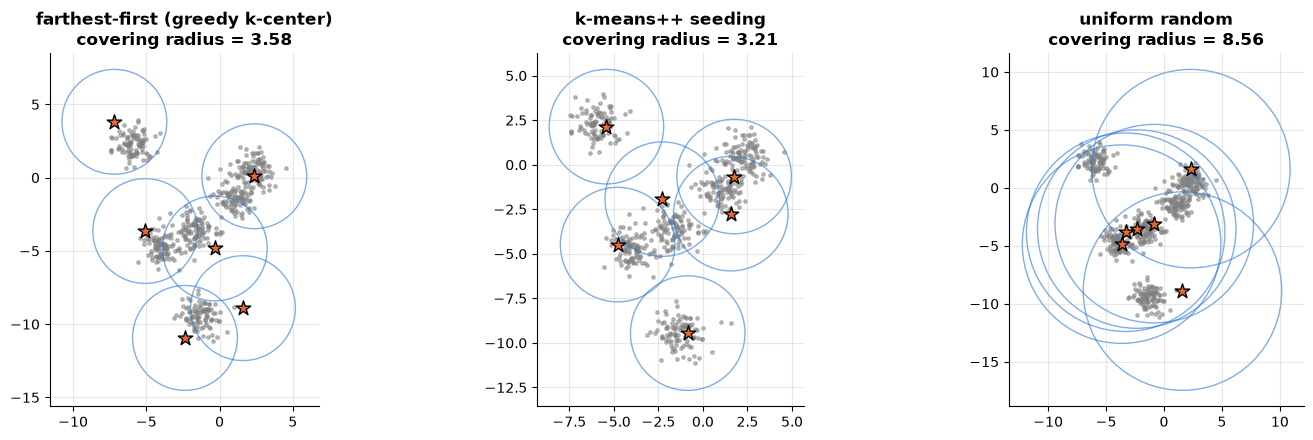

In [10]:
from sklearn.cluster import kmeans_plusplus
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=600, centers=6, cluster_std=0.7, random_state=2)
k = 6
gc, r_greedy = greedy_k_center(X, k)
pp, pp_idx = kmeans_plusplus(X, n_clusters=k, random_state=0)
rand_idx = np.random.default_rng(0).choice(len(X), k, replace=False)
results = {"farthest-first (greedy k-center)": (gc, r_greedy),
           "k-means++ seeding": (list(pp_idx), radius(X, list(pp_idx))),
           "uniform random": (list(rand_idx), radius(X, list(rand_idx)))}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, (cs, r)) in zip(axes, results.items()):
    ax.scatter(*X.T, s=6, color="gray", alpha=0.5)
    ax.scatter(*X[cs].T, s=120, marker="*", color=PALETTE[1], edgecolor="black", zorder=3)
    for c in cs:
        ax.add_patch(plt.Circle(X[c], r, fill=False, color=PALETTE[0], alpha=0.6))
    ax.set_title(f"{name}\ncovering radius = {r:.2f}"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

**What just happened?** On small instances greedy was always within the factor 2 of the brute-force optimum (typically much closer). On the blob data, farthest-first and k-means++ both reach small covering radii (k-means++ happened to be a little smaller here). Notice that farthest-first likes **extreme points**: its centres sit at cluster edges or on outliers, because it always jumps to the farthest point. That makes it great for worst-case coverage but sensitive to outliers. **k-means++** (Arthur & Vassilvitskii, 2007) is the randomized cousin: it samples the next centre with probability proportional to the *squared* distance, which gives an O(log k)-approximation in expectation for the k-means objective; it is the default seeding of scikit-learn's `KMeans`. Uniform random seeding put several centres into the same clusters and none into the bottom one, so its radius is more than twice as large. The exact radii are in the panel titles.

**Link to active learning.** "Core-set" active learning (Sener & Savarese, ICLR 2018) labels the points chosen by greedy k-center in a network's embedding space, so the labelled set covers the data with a small radius. See [`03_Machine_Learning/13_active_learning`](../../03_Machine_Learning/13_active_learning/01_active_learning.ipynb) and [`02_unsupervised/01_clustering`](../../03_Machine_Learning/02_unsupervised/01_clustering.ipynb).

---
## 7. Parameterized complexity: FPT vertex cover

> 💬 **In plain English:** if the answer is small (k), we can search all possibilities in time that explodes only in k, not in the input size.

Sometimes the hard part of a problem is a **parameter** k that is small in practice (the size of the solution, the treewidth of a graph, …). A problem is **fixed-parameter tractable (FPT)** if it can be solved in time **f(k) · poly(n)** for some computable function f. The exponential explosion is confined to k.

**Vertex cover of size ≤ k, by a bounded search tree.** Pick any uncovered edge (u, v). Any cover must contain u **or** v, so branch on the two choices, each time with budget k − 1. The search tree has depth ≤ k and at most 2ᵏ leaves; each node does O(n + m) work. Total: **O(2ᵏ · (n + m))**, so for k = 20 that is about a million times the graph size, whatever n is. Compare with brute force over all C(n, k) subsets, which is roughly nᵏ.

**Kernelization (Buss's rule).** A vertex of degree > k *must* be in the cover (otherwise all its > k neighbours would be). Take all such vertices. In what remains every degree is ≤ k, so if more than k'·k edges remain (k' = remaining budget), the answer is "no". Otherwise the remaining graph (the **kernel**) has O(k²) edges, independent of n. Kernelization is polynomial-time preprocessing that shrinks an instance to a size bounded by a function of k.

(The best known FPT algorithm for vertex cover runs in about O(1.2738ᵏ + kn) time; Chen, Kanj & Xia 2010.)

In [11]:
def vc_fpt(edges, k):
    """Is there a vertex cover of size <= k? Bounded search tree, O(2^k * m). Returns a cover or None."""
    if not edges:
        return set()                                  # nothing left to cover
    if k == 0:
        return None                                   # edges remain but no budget
    u, v = edges[0]                                   # this edge must be covered by u or by v
    for w in (u, v):
        rest = [e for e in edges if w not in e]       # put w in the cover: its edges are covered
        sub = vc_fpt(rest, k - 1)
        if sub is not None:
            return sub | {w}
    return None

def buss_kernel(edges, k):
    """Return (forced vertices, remaining edges, remaining budget), or None if clearly impossible."""
    forced = set()
    changed = True
    while changed:
        changed = False
        deg = Counter(x for e in edges for x in e)
        high = [x for x, d in deg.items() if d > k - len(forced)]
        if high:
            forced |= set(high); changed = True
            edges = [e for e in edges if e[0] not in forced and e[1] not in forced]
        if len(forced) > k:
            return None
    budget = k - len(forced)
    if len(edges) > budget * budget:
        return None                                   # max degree <= budget, so <= budget^2 edges coverable
    return forced, edges, budget

def vc_kernel_then_fpt(edges, k):
    kern = buss_kernel(edges, k)
    if kern is None:
        return None
    forced, rest, budget = kern
    sub = vc_fpt(rest, budget)
    return None if sub is None else forced | sub

# Correctness against the exact optimum on random small graphs
rng = random.Random(6)
for t in range(150):
    G = nx.gnp_random_graph(rng.randint(2, 12), rng.uniform(0.1, 0.5), seed=t)
    edges = list(G.edges()); opt = len(min_vertex_cover_exact(G))
    for k in range(0, opt + 2):
        for solver in (vc_fpt, vc_kernel_then_fpt):
            C = solver(edges, k)
            assert (C is not None) == (k >= opt)
            if C is not None: assert len(C) <= k and is_vertex_cover(G, C)
print("FPT and kernel+FPT give exact answers on 150 random graphs (every k)")

FPT and kernel+FPT give exact answers on 150 random graphs (every k)


In [12]:
def planted_vc_graph(n, k, m, seed):
    """Random graph with m edges, each touching a planted set of k vertices (so a cover of size k exists)."""
    r = random.Random(seed)
    planted = list(range(k)); edges = set()
    while len(edges) < m:
        u = r.choice(planted); v = r.randrange(n)
        if u != v: edges.add((min(u, v), max(u, v)))
    return list(edges)

rows = []
for n in [100, 1_000, 10_000]:
    for k in [4, 8, 12]:
        edges = planted_vc_graph(n, k, m=3 * n, seed=n + k)
        t0 = time.perf_counter(); C = vc_kernel_then_fpt(edges, k); t_kernel = time.perf_counter() - t0
        assert C is not None and len(C) <= k
        rows.append({"n": n, "k": k, "edges": len(edges), "kernel+FPT (s)": round(t_kernel, 4),
                     "brute force subsets C(n,k)": f"{math.comb(n, k):.1e}"})
print(pd.DataFrame(rows).to_string(index=False))

# Pure bounded search (no kernel) on a graph whose cover needs exactly k vertices: time grows ~2^k
rows = []
for k in range(4, 15, 2):
    edges = [(i, k + i) for i in range(k)]                  # k disjoint edges: needs exactly k vertices
    edges += [(i, 2 * k + j) for i in range(k) for j in range(3)]
    stats = {"calls": 0}
    def counted(edges, k):
        stats["calls"] += 1
        if not edges: return set()
        if k == 0: return None
        u, v = edges[0]
        for w in (u, v):
            sub = counted([e for e in edges if w not in e], k - 1)
            if sub is not None: return sub | {w}
        return None
    assert counted(edges, k - 1) is None                    # prove that k - 1 vertices are NOT enough
    rows.append({"k": k, "search-tree nodes to prove 'no' with budget k-1": stats["calls"], "2^k": 2**k})
print(pd.DataFrame(rows).to_string(index=False))

    n  k  edges  kernel+FPT (s) brute force subsets C(n,k)
  100  4    300          0.0003                    3.9e+06
  100  8    300          0.0003                    1.9e+11
  100 12    300          0.0003                    1.1e+15
 1000  4   3000          0.0136                    4.1e+10
 1000  8   3000          0.0130                    2.4e+19
 1000 12   3000          0.0085                    2.0e+27
10000  4  30000          0.1042                    4.2e+14
10000  8  30000          0.1431                    2.5e+27
10000 12  30000          0.0535                    2.1e+39


 k  search-tree nodes to prove 'no' with budget k-1   2^k
 4                                               15    16
 6                                               63    64
 8                                              255   256
10                                             1023  1024
12                                             4095  4096
14                                            16383 16384


**What just happened?**
- Both FPT solvers gave exactly the right yes/no answer for every budget k on 150 random graphs, and every cover they returned was valid.
- With the kernel, graphs with up to 10,000 vertices and a planted cover of size 12 are solved quickly, even though brute force would need to examine an astronomically large number of subsets (last column). The running time depends mainly on k, not n.
- The second table proves "no" answers (budget k − 1 where k vertices are needed). The search tree is a complete binary tree of depth k − 1, with exactly 2ᵏ − 1 nodes: the running time doubles with every +1 in k, and the graph size plays almost no role. That is exactly what f(k)·poly(n) means.

> 🎓 **Exam / interview tip:** not every NP-hard problem is FPT in its natural parameter. Vertex cover is FPT in k, but **clique** and **independent set** of size k are believed not to be (they are W[1]-hard), so nothing much better than n^Θ(k) is expected.

---
## 8. Inapproximability: general TSP cannot be approximated

> 💬 **In plain English:** some problems are so hard that even a rough approximation would solve an NP-complete problem.

Without the triangle inequality, TSP has **no ρ-approximation for any constant ρ** unless P = NP (Sahni & Gonzalez 1976; CLRS Theorem 35.3).

**Proof by reduction from HAMILTONIAN-CYCLE.** Given a graph G with n vertices, build a complete graph where an edge costs **1** if it is in G and **ρn + 1** otherwise.
- If G has a Hamiltonian cycle, that cycle is a tour of cost exactly n.
- If not, every tour uses at least one non-edge, so it costs ≥ (ρn + 1) + (n − 1) > ρn.

A ρ-approximation would return a tour of cost ≤ ρn exactly when G is Hamiltonian, so it would decide an NP-complete problem in polynomial time. ∎ The gap between n and ρn is what kills approximation.

In [13]:
def tsp_from_ham(G, rho):
    n = G.number_of_nodes(); nodes = list(G.nodes()); idx = {v: i for i, v in enumerate(nodes)}
    D = np.full((n, n), rho * n + 1.0)
    for u, v in G.edges():
        D[idx[u], idx[v]] = D[idx[v], idx[u]] = 1.0
    np.fill_diagonal(D, 0)
    return D

rho = 2
rng = random.Random(2)
ham_graph = nx.cycle_graph(10)                                    # Hamiltonian by construction...
ham_graph.add_edges_from((rng.randrange(10), rng.randrange(10)) for _ in range(6))   # ...plus random chords
ham_graph.remove_edges_from(nx.selfloop_edges(ham_graph))
for name, G in [("cycle + chords (Hamiltonian)", ham_graph), ("Petersen graph (not Hamiltonian)", nx.petersen_graph())]:
    D = tsp_from_ham(G, rho)
    opt = held_karp(D)
    n = G.number_of_nodes()
    print(f"{name:34s}: optimal tour = {opt:5.0f};  n = {n}, ρn = {rho * n}  → "
          f"{'tour ≤ ρn: a ρ-approx would answer YES' if opt <= rho * n else 'every tour > ρn: a ρ-approx would answer NO'}")

cycle + chords (Hamiltonian)      : optimal tour =    10;  n = 10, ρn = 20  → tour ≤ ρn: a ρ-approx would answer YES
Petersen graph (not Hamiltonian)  : optimal tour =    30;  n = 10, ρn = 20  → every tour > ρn: a ρ-approx would answer NO


**What just happened?** The Hamiltonian graph gives an optimal tour of cost exactly n = 10, while the Petersen graph (famously non-Hamiltonian) forces every tour above ρn = 20. Any 2-approximation would therefore separate the two cases, which no polynomial algorithm can do unless P = NP.

**Known approximability landscape (assuming P ≠ NP):**

| Problem | Best ratio known | Hardness of approximation |
|---|---|---|
| vertex cover | 2 | no √2 − ε (2 − ε under the Unique Games Conjecture) |
| set cover | H(n) ≈ ln n | no (1 − ε) ln n |
| metric TSP | 1.5 − 10⁻³⁶ | no 123/122 (Karpinski, Lampis & Schmied 2015) |
| general TSP | none | no constant ratio at all |
| k-center | 2 | no 2 − ε |
| knapsack | FPTAS: 1 + ε for any ε | – |
| MAX-3SAT | 8/7 (random assignment satisfies 7/8 of clauses) | no 8/7 − ε (Håstad 2001) |

---
## 9. 🔗 How this connects to modern AI: submodular maximisation for RAG

> 💬 **In plain English:** for 'diminishing returns' goals, greedy picking is guaranteed to get at least 63 % of the best possible value.

When a RAG system ([`08_LLM/02_rag`](../../08_LLM/02_rag/01_rag_fundamentals.ipynb)) fills an LLM's limited context window, the top-k most *similar* chunks are often near-duplicates of each other. We want a set that is **relevant and diverse**. Many such "coverage" objectives are **submodular**: adding a document to a small set helps at least as much as adding it to a bigger set (diminishing returns). Formally, for S ⊆ T and x ∉ T: f(S ∪ {x}) − f(S) ≥ f(T ∪ {x}) − f(T).

**Theorem (Nemhauser, Wolsey & Fisher 1978).** For a monotone submodular f with f(∅) = 0, the greedy algorithm that adds the item with the largest **marginal gain** k times achieves f(S_greedy) ≥ **(1 − 1/e)·OPT ≈ 0.632·OPT**. Doing better is NP-hard (Feige 1998). Set cover's greedy and maximum coverage are special cases.

We use the **facility-location** objective f(S) = Σᵢ relᵢ · max_{j∈S} sim(i, j): every chunk i (weighted by its relevance relᵢ to the query) is "represented" by its most similar selected chunk. It is monotone submodular when similarities are ≥ 0. Related ideas: **MMR** (maximal marginal relevance) reranking, extractive summarisation (Lin & Bilmes 2011) and data-subset selection for training.

In [14]:
# Synthetic "chunk embeddings": 5 topics, with many near-duplicates of the most relevant topic
rng_np = np.random.default_rng(11)
topic_centres = rng_np.normal(size=(5, 16))
topic_of = np.array([0] * 12 + [1] * 5 + [2] * 5 + [3] * 4 + [4] * 4)      # topic 0 is over-represented
E = topic_centres[topic_of] + 0.25 * rng_np.normal(size=(len(topic_of), 16))
E /= np.linalg.norm(E, axis=1, keepdims=True)
query = topic_centres[0] + 0.8 * topic_centres[1] + 0.6 * topic_centres[2] + 0.4 * topic_centres[3]
query /= np.linalg.norm(query)
rel = np.clip(E @ query, 0, None)                    # relevance of each chunk to the query
S_mat = np.clip(E @ E.T, 0, None)                    # non-negative cosine similarities

def facility_location(S):
    if not S: return 0.0
    return float(rel @ S_mat[:, list(S)].max(axis=1))

def greedy_submodular(f, n, k):
    chosen = []
    for _ in range(k):
        gains = [(f(chosen + [j]) - f(chosen), j) for j in range(n) if j not in chosen]
        chosen.append(max(gains)[1])                  # largest marginal gain
    return chosen

k, n = 4, len(topic_of)
greedy_set = greedy_submodular(facility_location, n, k)
topk_set = list(np.argsort(-rel)[:k])                # plain "top-k by similarity"
t0 = time.perf_counter()
opt_val = max(facility_location(list(c)) for c in itertools.combinations(range(n), k))
t_opt = time.perf_counter() - t0
res = pd.DataFrame([
    {"method": "top-k by relevance", "f(S)": facility_location(topk_set), "topics covered": len(set(topic_of[topk_set])),
     "chosen topics": list(topic_of[topk_set])},
    {"method": "greedy submodular", "f(S)": facility_location(greedy_set), "topics covered": len(set(topic_of[greedy_set])),
     "chosen topics": list(topic_of[greedy_set])},
    {"method": f"exhaustive optimum ({math.comb(n, k):,} subsets)", "f(S)": opt_val, "topics covered": None, "chosen topics": None}])
res["f / OPT"] = res["f(S)"] / opt_val
print(res.round(4).to_string(index=False))
print(f"(1 - 1/e) = {1 - 1/math.e:.3f};  exhaustive search took {t_opt:.2f} s, greedy needs only {n * k} evaluations")
assert facility_location(greedy_set) >= (1 - 1 / math.e) * opt_val

                             method    f(S)  topics covered chosen topics  f / OPT
                 top-k by relevance  8.0578             1.0  [0, 0, 0, 0]   0.6945
                  greedy submodular 11.5362             4.0  [0, 1, 2, 3]   0.9942
exhaustive optimum (27,405 subsets) 11.6031             NaN          None   1.0000
(1 - 1/e) = 0.632;  exhaustive search took 1.36 s, greedy needs only 120 evaluations


**What just happened?** Plain top-k by relevance fills the context with near-duplicates from the over-represented topic 0 (look at the "chosen topics" column), so it covers fewer topics and scores lower on the coverage objective. The greedy submodular choice picks one strong representative and then the next most *useful* (not most similar) chunks, covering more topics. Its objective value is very close to the exhaustive optimum, far above the worst-case (1 − 1/e) ≈ 0.632 guarantee, using 120 evaluations instead of tens of thousands.

Other places where approximation algorithms appear in AI and ML systems:
- **k-means++** and core-set selection (section 6), and greedy feature selection.
- **Scheduling** GPU jobs and **bin packing** model shards onto devices (first-fit decreasing has ratio 11/9·OPT + 6/9).
- **Vehicle routing** for logistics, with Christofides/2-opt style construction and improvement ([`classical_ai/11`](../classical_ai/11_industry_route_planning_and_scheduling.ipynb)).
- **Influence maximisation** in social networks (Kempe, Kleinberg & Tardos 2003) uses the same (1 − 1/e) greedy.

---
## Recap
- A **ρ-approximation** is within factor ρ of optimal on *every* input. Proofs work by comparing with a computable **bound on OPT** (a matching for vertex cover, the MST for TSP, pigeonhole for k-center).
- **Vertex cover**: both endpoints of a maximal matching, ratio 2, tight.
- **Set cover**: greedy, ratio H(n) ≈ ln n, and that is essentially optimal.
- **Metric TSP**: double tree (2), Christofides (1.5); 2-opt polishes tours in practice; Held–Karp is exact but O(n²2ⁿ).
- **Knapsack** has an FPTAS: round values with K = ε·v_max/n and run the value DP; value ≥ (1 − ε)·OPT in O(n³/ε).
- **k-center**: farthest-first traversal, ratio 2; k-means++ is its randomized cousin.
- **FPT**: vertex cover of size k in O(2ᵏ·(n + m)); kernels shrink inputs to size depending only on k.
- Some problems **cannot** be approximated: general TSP has no constant ratio unless P = NP.
- **Monotone submodular** objectives are maximised within (1 − 1/e) by greedy, which is how coverage-style diverse selection (RAG context, summarisation, influence maximisation) is done.

## Practice problems

**1. (Easy, conceptual)** An algorithm for a minimisation problem returns a solution of cost 150 on an instance whose optimal cost is 100. On another instance, it returns 90 when OPT is 60. What can you say about its approximation ratio?

<details><summary>Show solution</summary>

The ratio is the **worst case over all inputs**, so it is at least max(150/100, 90/60) = **1.5**. Two examples can only show a *lower bound* on ρ; to claim ρ = 1.5 you need a proof covering every input.

</details>

**2. (Easy, conceptual)** Why is it wrong to take only *one* endpoint of each matched edge in the vertex-cover algorithm?

<details><summary>Show solution</summary>

The result may not be a cover. Take the path a–b–c–d with matching {(a, b), (c, d)}: choosing a and d leaves the edge (b, c) uncovered. Taking both endpoints guarantees that every edge touches a matched vertex: otherwise that edge could have been added to the matching, contradicting maximality.

</details>

**3. (Medium, coding)** **Maximum coverage:** choose k sets to cover as many elements as possible. Implement the greedy algorithm and check the (1 − 1/e) guarantee against brute force.

<details><summary>Show solution</summary>

```python
def greedy_max_coverage(sets, k):
    """Pick k sets to maximise the number of covered elements: a (1 - 1/e)-approximation."""
    covered, chosen = set(), []
    for _ in range(min(k, len(sets))):
        i = max(range(len(sets)), key=lambda j: len(sets[j] - covered))   # largest marginal gain
        chosen.append(i); covered |= sets[i]
    return chosen, len(covered)
```
Coverage f(S) = |∪S| is monotone submodular, so the Nemhauser–Wolsey–Fisher theorem gives f(greedy) ≥ (1 − 1/e)·OPT. Tested on 200 random instances.

</details>

**4. (Hard, coding)** **Weighted vertex cover by LP rounding.** Solve the LP relaxation (0 ≤ x_v ≤ 1, x_u + x_v ≥ 1 per edge, minimise Σ w_v x_v) with `scipy.optimize.linprog` and take every vertex with x_v ≥ ½. Prove and test that this is a 2-approximation.

<details><summary>Show solution</summary>

```python
import numpy as np
from scipy.optimize import linprog

def weighted_vc_lp_rounding(n, edges, w):
    """LP relaxation: min Σ w_v x_v  s.t.  x_u + x_v >= 1 for each edge, 0 <= x <= 1.
    Round: take every v with x_v >= 1/2. Weight <= 2 * LP <= 2 * OPT."""
    A = np.zeros((len(edges), n))
    for r, (u, v) in enumerate(edges):
        A[r, u] = A[r, v] = -1                       # -(x_u + x_v) <= -1
    res = linprog(c=w, A_ub=A, b_ub=-np.ones(len(edges)), bounds=[(0, 1)] * n, method="highs")
    cover = {v for v in range(n) if res.x[v] >= 0.5 - 1e-9}
    return cover, res.fun
```
**Cover:** for each edge x_u + x_v ≥ 1, so at least one of them is ≥ ½ and is taken. **Ratio:** every chosen v has 2x_v ≥ 1, so w(C) ≤ Σ 2w_v x_v = 2·LP ≤ 2·OPT, because the LP is a relaxation of the integer problem (LP ≤ OPT). Tested on 60 random weighted graphs against brute force. (This is CLRS §35.4; the matching algorithm of section 2 does not handle weights.)

</details>

**5. (Medium, coding)** **Bin packing, First Fit.** Implement First Fit for items of size in (0, 1] and bins of capacity 1. Show it uses at most 2·OPT bins.

<details><summary>Show solution</summary>

```python
import math

def first_fit(items, capacity=1.0):
    """Put each item into the first bin with room; open a new bin if none fits."""
    bins = []
    for x in items:
        for b in bins:
            if sum(b) + x <= capacity + 1e-12:
                b.append(x); break
        else:
            bins.append([x])
    return bins
```
**Proof:** in a First-Fit packing, at most one bin is at most half full (if two bins were both ≤ ½ full, the later bin's items would have fitted into the earlier bin). So with B bins, total size > (B − 1)/2, giving B < 2·total + 1, i.e. B ≤ 2⌈total⌉ ≤ 2·OPT, since OPT ≥ ⌈total⌉. Tested on 300 random instances using the lower bound OPT ≥ ⌈Σ sizes⌉. (A sharper analysis gives First Fit ≤ ⌊1.7·OPT⌋, Dósa & Sgall 2013.)

</details>

**6. (Medium, conceptual)** What is the difference between a PTAS and an FPTAS? Can a strongly NP-hard problem (with integer objective values bounded by a polynomial in n) have an FPTAS?

<details><summary>Show solution</summary>

A **PTAS** runs in time polynomial in n for each fixed ε, e.g. O(n^(1/ε)). An **FPTAS** must be polynomial in both n and 1/ε, e.g. O(n³/ε). **No FPTAS** for such problems unless P = NP: if OPT ≤ p(n) (an integer), run the FPTAS with ε = 1/(p(n) + 1). The error is then < 1, so the answer is exactly optimal, in time polynomial in n, which would solve a strongly NP-hard problem in polynomial time.

</details>

**7. (Hard, conceptual)** Show that the greedy k-center algorithm is still a 2-approximation if the first centre is chosen arbitrarily, and give an instance where the ratio is exactly 2.

<details><summary>Show solution</summary>

The proof in section 6 never uses how the first centre was chosen: the final k centres plus the farthest point p are k + 1 points pairwise ≥ r apart, so two share an optimal centre, giving r ≤ 2·OPT. **Tight instance:** points 0, 1, 2 on a line with k = 1. OPT puts the centre at 1, radius 1. If greedy starts at 0, its radius is 2 = 2·OPT.

</details>

## Further reading (additional learning resources)
- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS, 4th ed., 2022), ch. 35 (approximation algorithms).
- Williamson & Shmoys, *The Design of Approximation Algorithms* (Cambridge, 2011), free PDF at https://www.designofapproxalgs.com/
- Vazirani, *Approximation Algorithms* (Springer, 2001).
- Kleinberg & Tardos, *Algorithm Design*, ch. 10 (extending tractability, FPT) and ch. 11 (approximation).
- Cygan et al., *Parameterized Algorithms* (Springer, 2015), free PDF from the authors.
- Krause & Golovin, "Submodular Function Maximization" (2014 survey).
- GeeksforGeeks: [Approximation algorithms](https://www.geeksforgeeks.org/approximation-algorithms/).

## Next notebook
➡️ [04 · Network flows and matching](04_network_flows_and_matching.ipynb): max-flow, min-cut, bipartite matching and the Hungarian algorithm, problems that look hard but are solvable exactly in polynomial time.